# P1 baseline — S1 DCA $100/month, 2026 Q1–Q3

Buy $100 at the open of each month's first available 1D bar, January through September: 9 buys, $900 total.
Top panel is the same candles as `plot-1d-ohlc.ipynb` with each buy marked; bottom panel is the holdings' USD value at each close against dollars invested so far.

- Zero fees and slippage; fills at the bar open. No QQQ dividends yet.
- Not-yet-invested dollars sit in cash at 0% and are not drawn in the value line.
- **XAUT** uses MT5 **XAUUSD** spot gold as a stand-in.

In [1]:
from helpers.replayer_bars import DATA_SYMBOL, period_bars
from helpers.passive_benchmarks import CAPITAL, plot_dca, simulate

SYMBOLS = ["BTC", "ETH", "XAUT", "QQQ"]
TIMEFRAME, START, END = "1d", "2026Q1", "2026Q3"
LABEL = "2026 Q1–Q3"

bars = {symbol: period_bars(symbol, TIMEFRAME, START, END) for symbol in SYMBOLS}
for symbol, price in bars.items():
    sim = simulate(price)
    units, dca, bh = sim["dca_units"].iloc[-1], sim["dca"].iloc[-1], sim["buy_hold"].iloc[-1]
    print(f"{symbol:<5} {sim['dca_buy'].sum()} buys -> {units:.6g} units, avg cost {CAPITAL / units:>10,.2f} | "
          f"{price.index[-1]:%Y-%m-%d} worth ${dca:,.2f} ({dca / CAPITAL - 1:+.1%}) vs buy & hold ${bh:,.2f} ({bh / CAPITAL - 1:+.1%})")

BTC   9 buys -> 0.0126042 units, avg cost  71,404.78 | 2026-09-30 worth $1,053.92 (+17.1%) vs buy & hold $858.65 (-4.6%)
ETH   9 buys -> 0.424766 units, avg cost   2,118.82 | 2026-09-30 worth $1,140.75 (+26.8%) vs buy & hold $813.39 (-9.6%)
XAUT  9 buys -> 0.199769 units, avg cost   4,505.20 | 2026-09-30 worth $830.44 (-7.7%) vs buy & hold $866.40 (-3.7%)
QQQ   9 buys -> 1.3687 units, avg cost     657.56 | 2026-09-30 worth $1,016.64 (+13.0%) vs buy & hold $1,077.24 (+19.7%)


In [2]:
for symbol, price in bars.items():
    sim = simulate(price)
    print(symbol, " ".join(f"{t:%m-%d}@{o:,.2f}" for t, o in price['open'][sim['dca_buy']].items()))

BTC 01-01@87,643.30 02-01@78,737.70 03-01@66,970.70 04-01@68,281.50 05-01@76,338.30 06-01@73,683.60 07-01@58,631.00 08-01@62,885.80 09-01@78,580.80
ETH 01-01@2,971.58 02-01@2,451.82 03-01@1,964.43 04-01@2,105.78 05-01@2,257.79 06-01@2,007.17 07-01@1,572.17 08-01@1,862.46 09-01@2,467.77
XAUT 01-02@4,318.21 02-02@4,813.48 03-02@5,299.74 04-01@4,670.68 05-01@4,630.84 06-01@4,539.55 07-01@4,012.20 08-03@4,076.52 09-01@4,448.48
QQQ 01-02@620.57 02-02@615.26 03-02@596.95 04-01@581.19 05-01@667.91 06-01@741.19 07-01@732.38 08-03@692.39 09-01@715.11


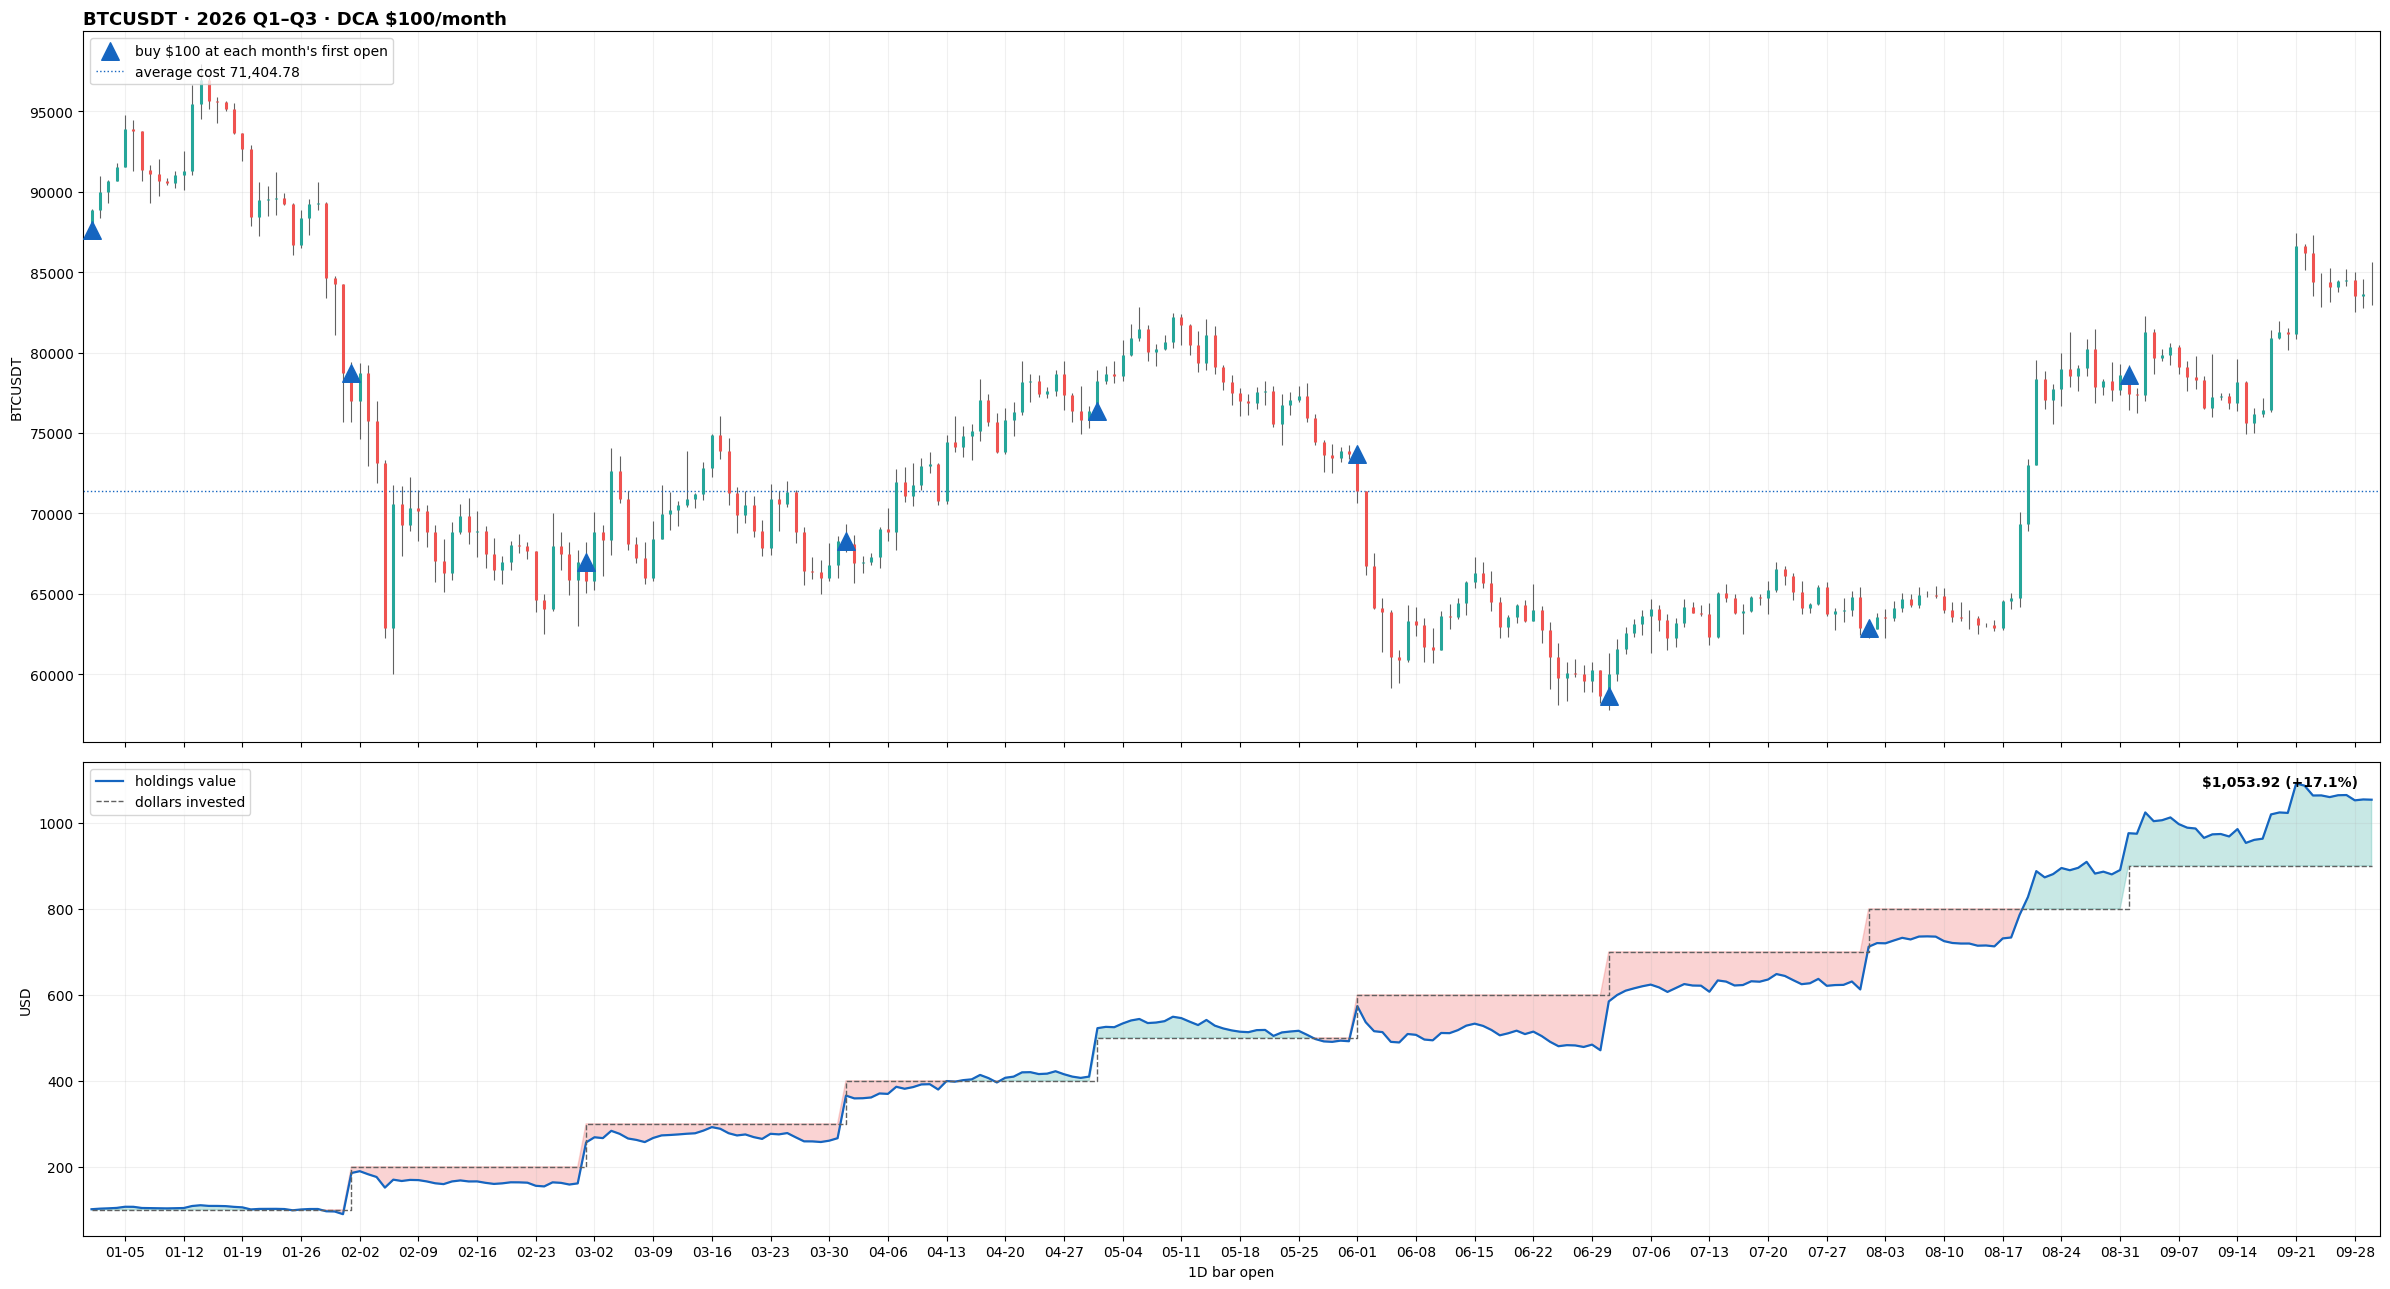

In [3]:
plot_dca(bars["BTC"], f"BTCUSDT · {LABEL} · DCA $100/month", "BTCUSDT")

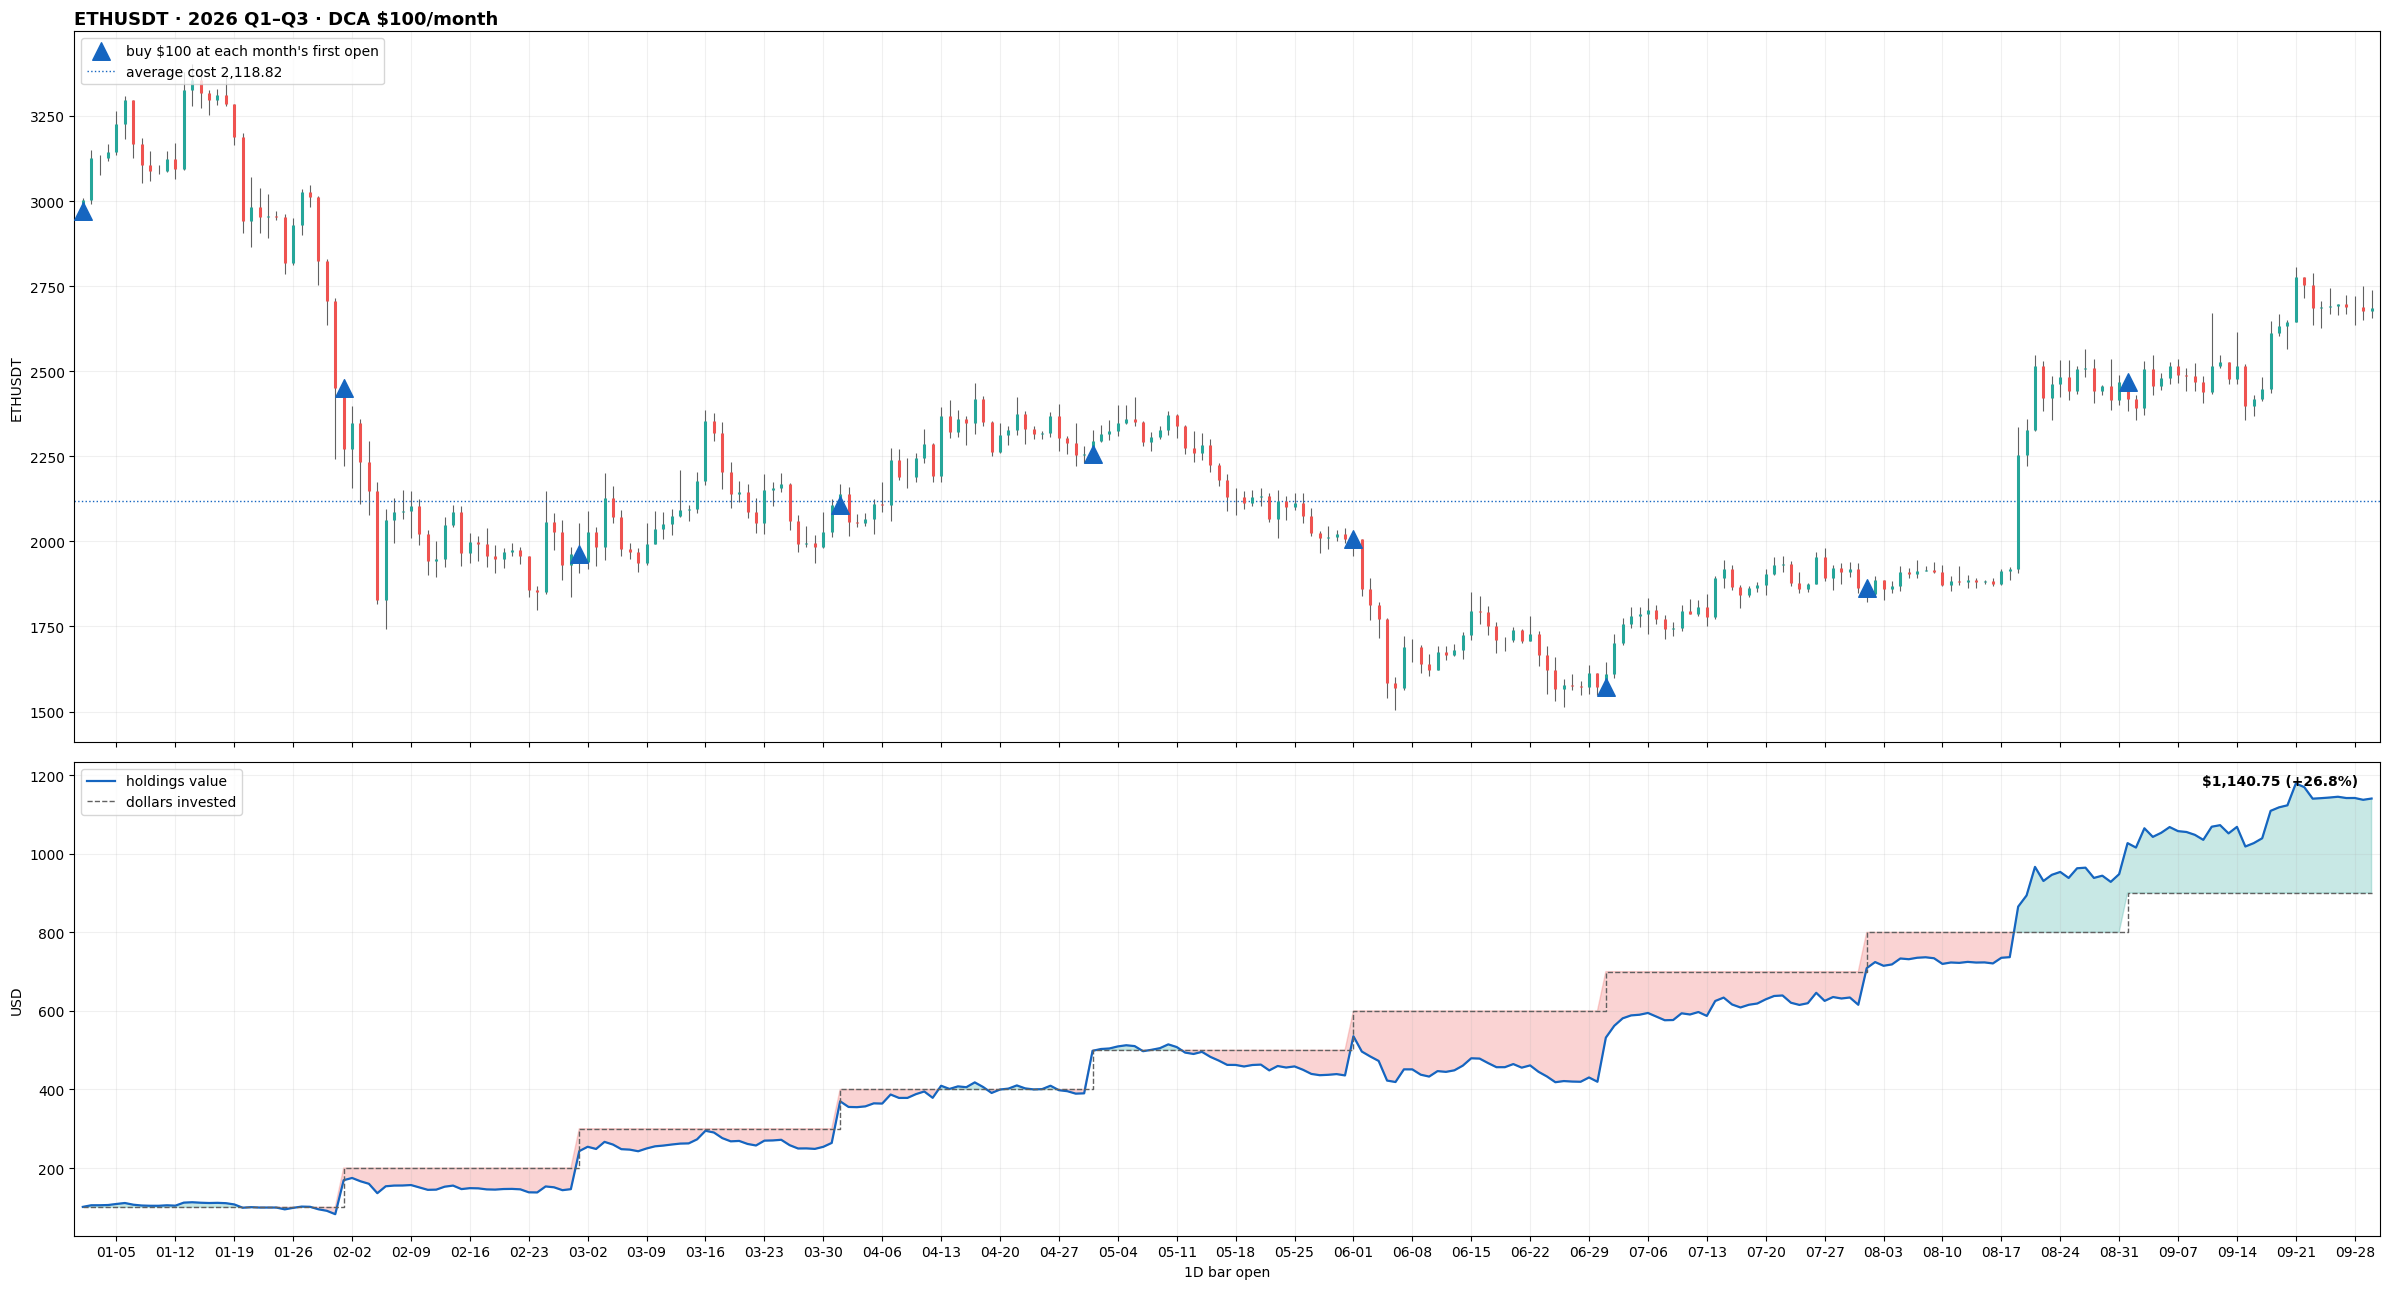

In [4]:
plot_dca(bars["ETH"], f"ETHUSDT · {LABEL} · DCA $100/month", "ETHUSDT")

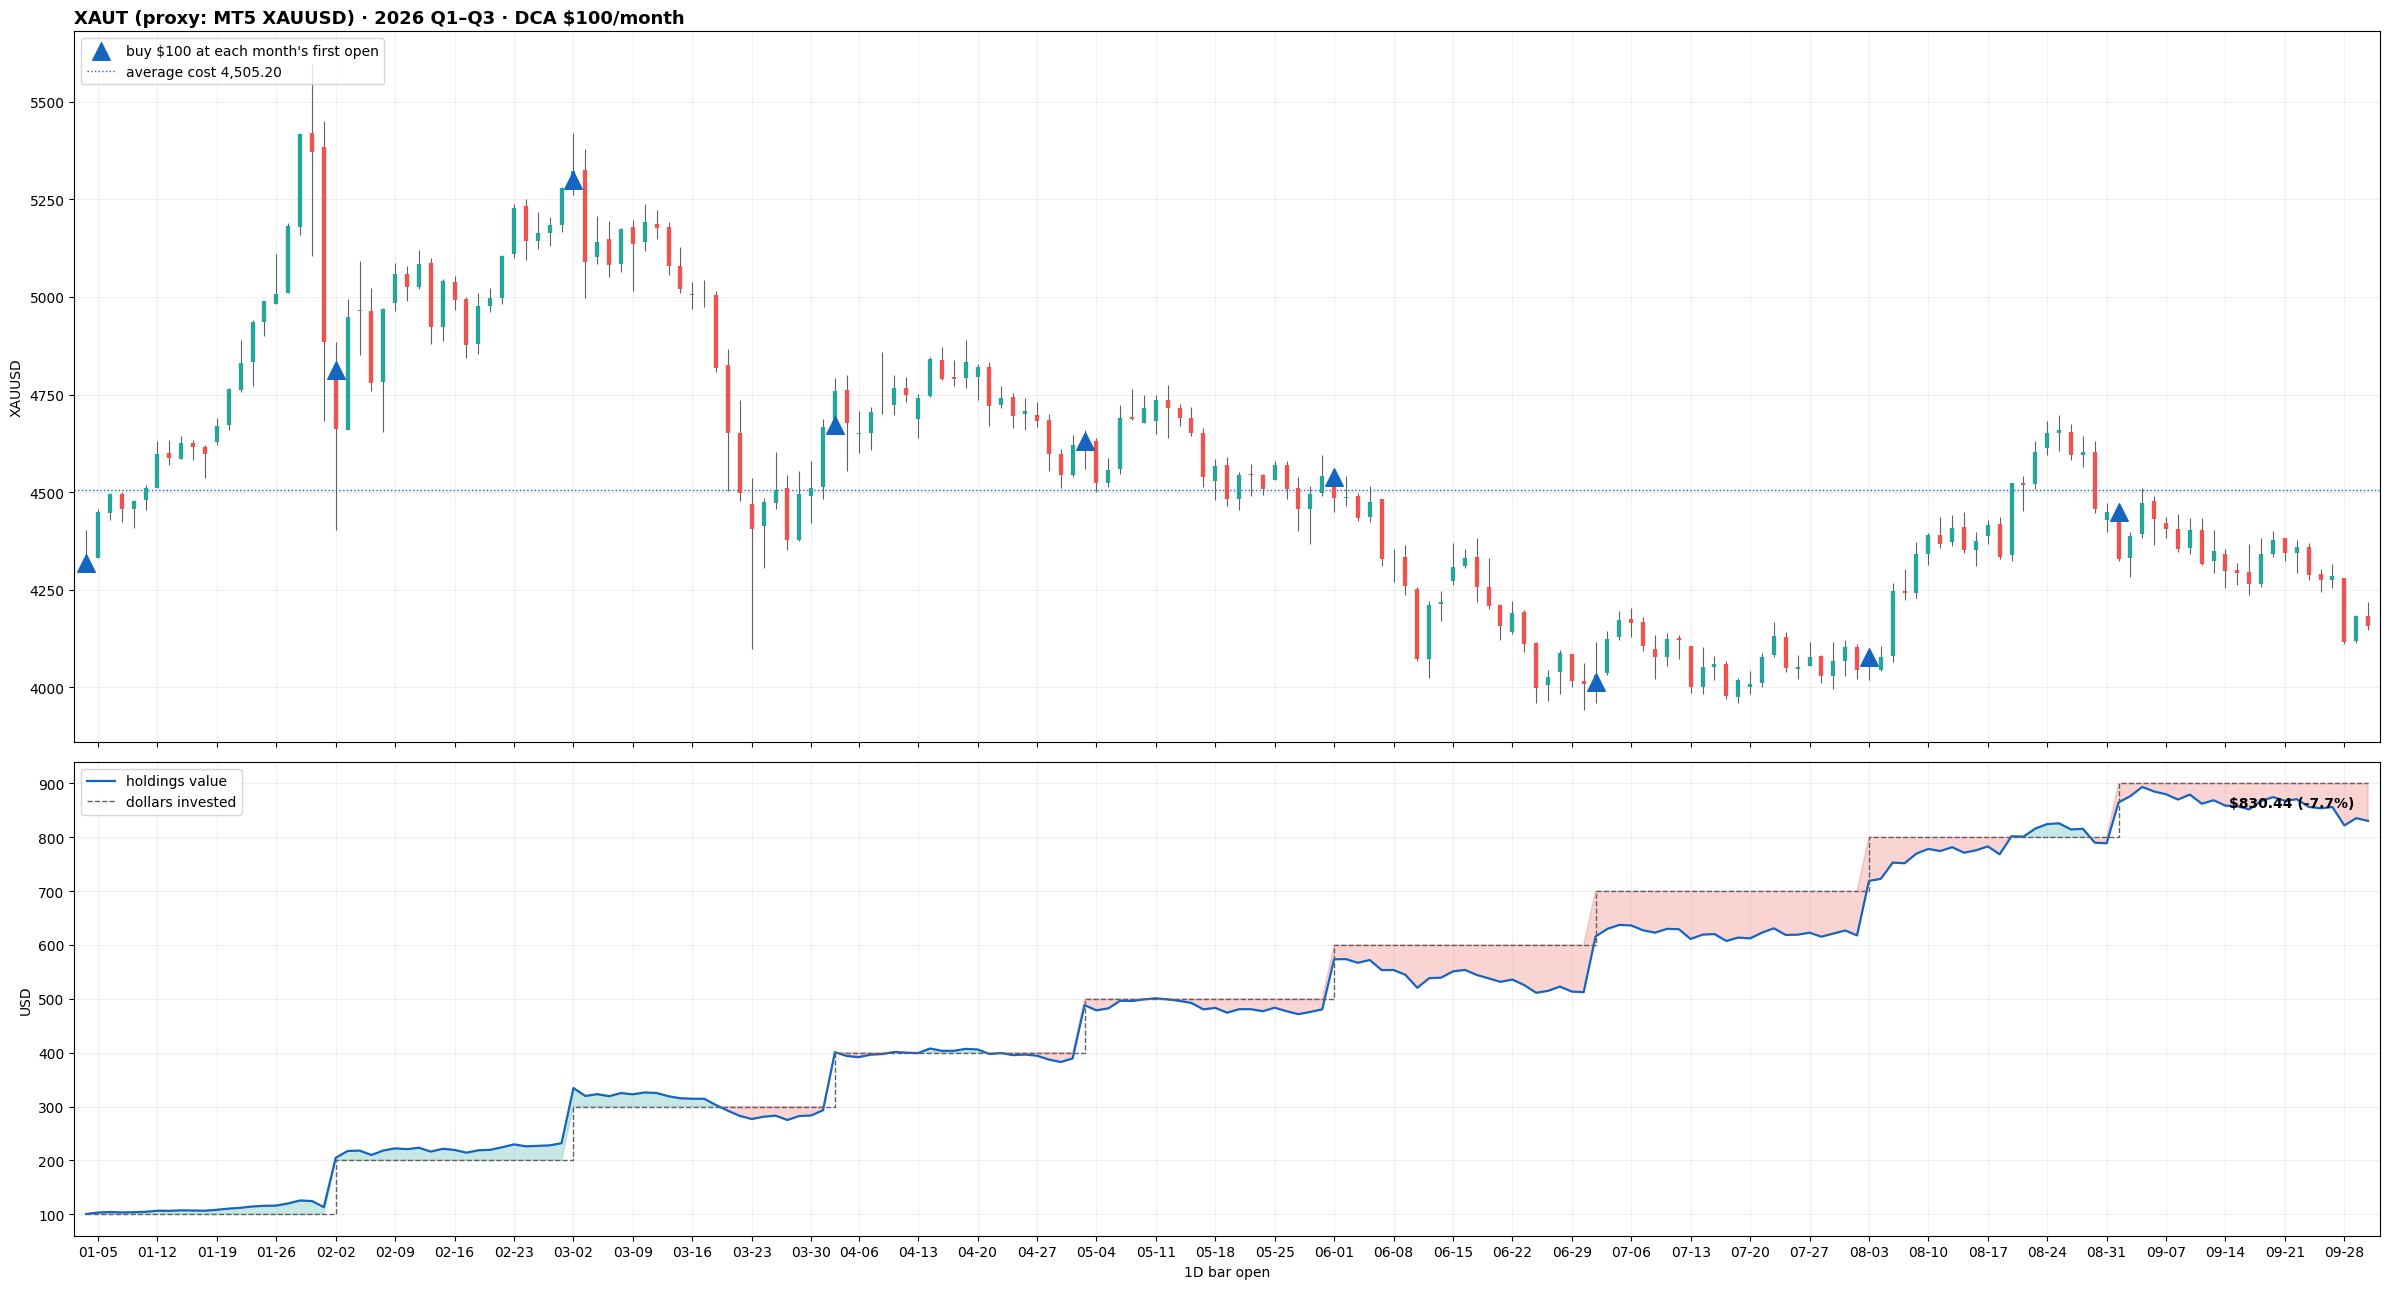

In [5]:
plot_dca(bars["XAUT"], f"XAUT (proxy: MT5 XAUUSD) · {LABEL} · DCA $100/month", "XAUUSD")

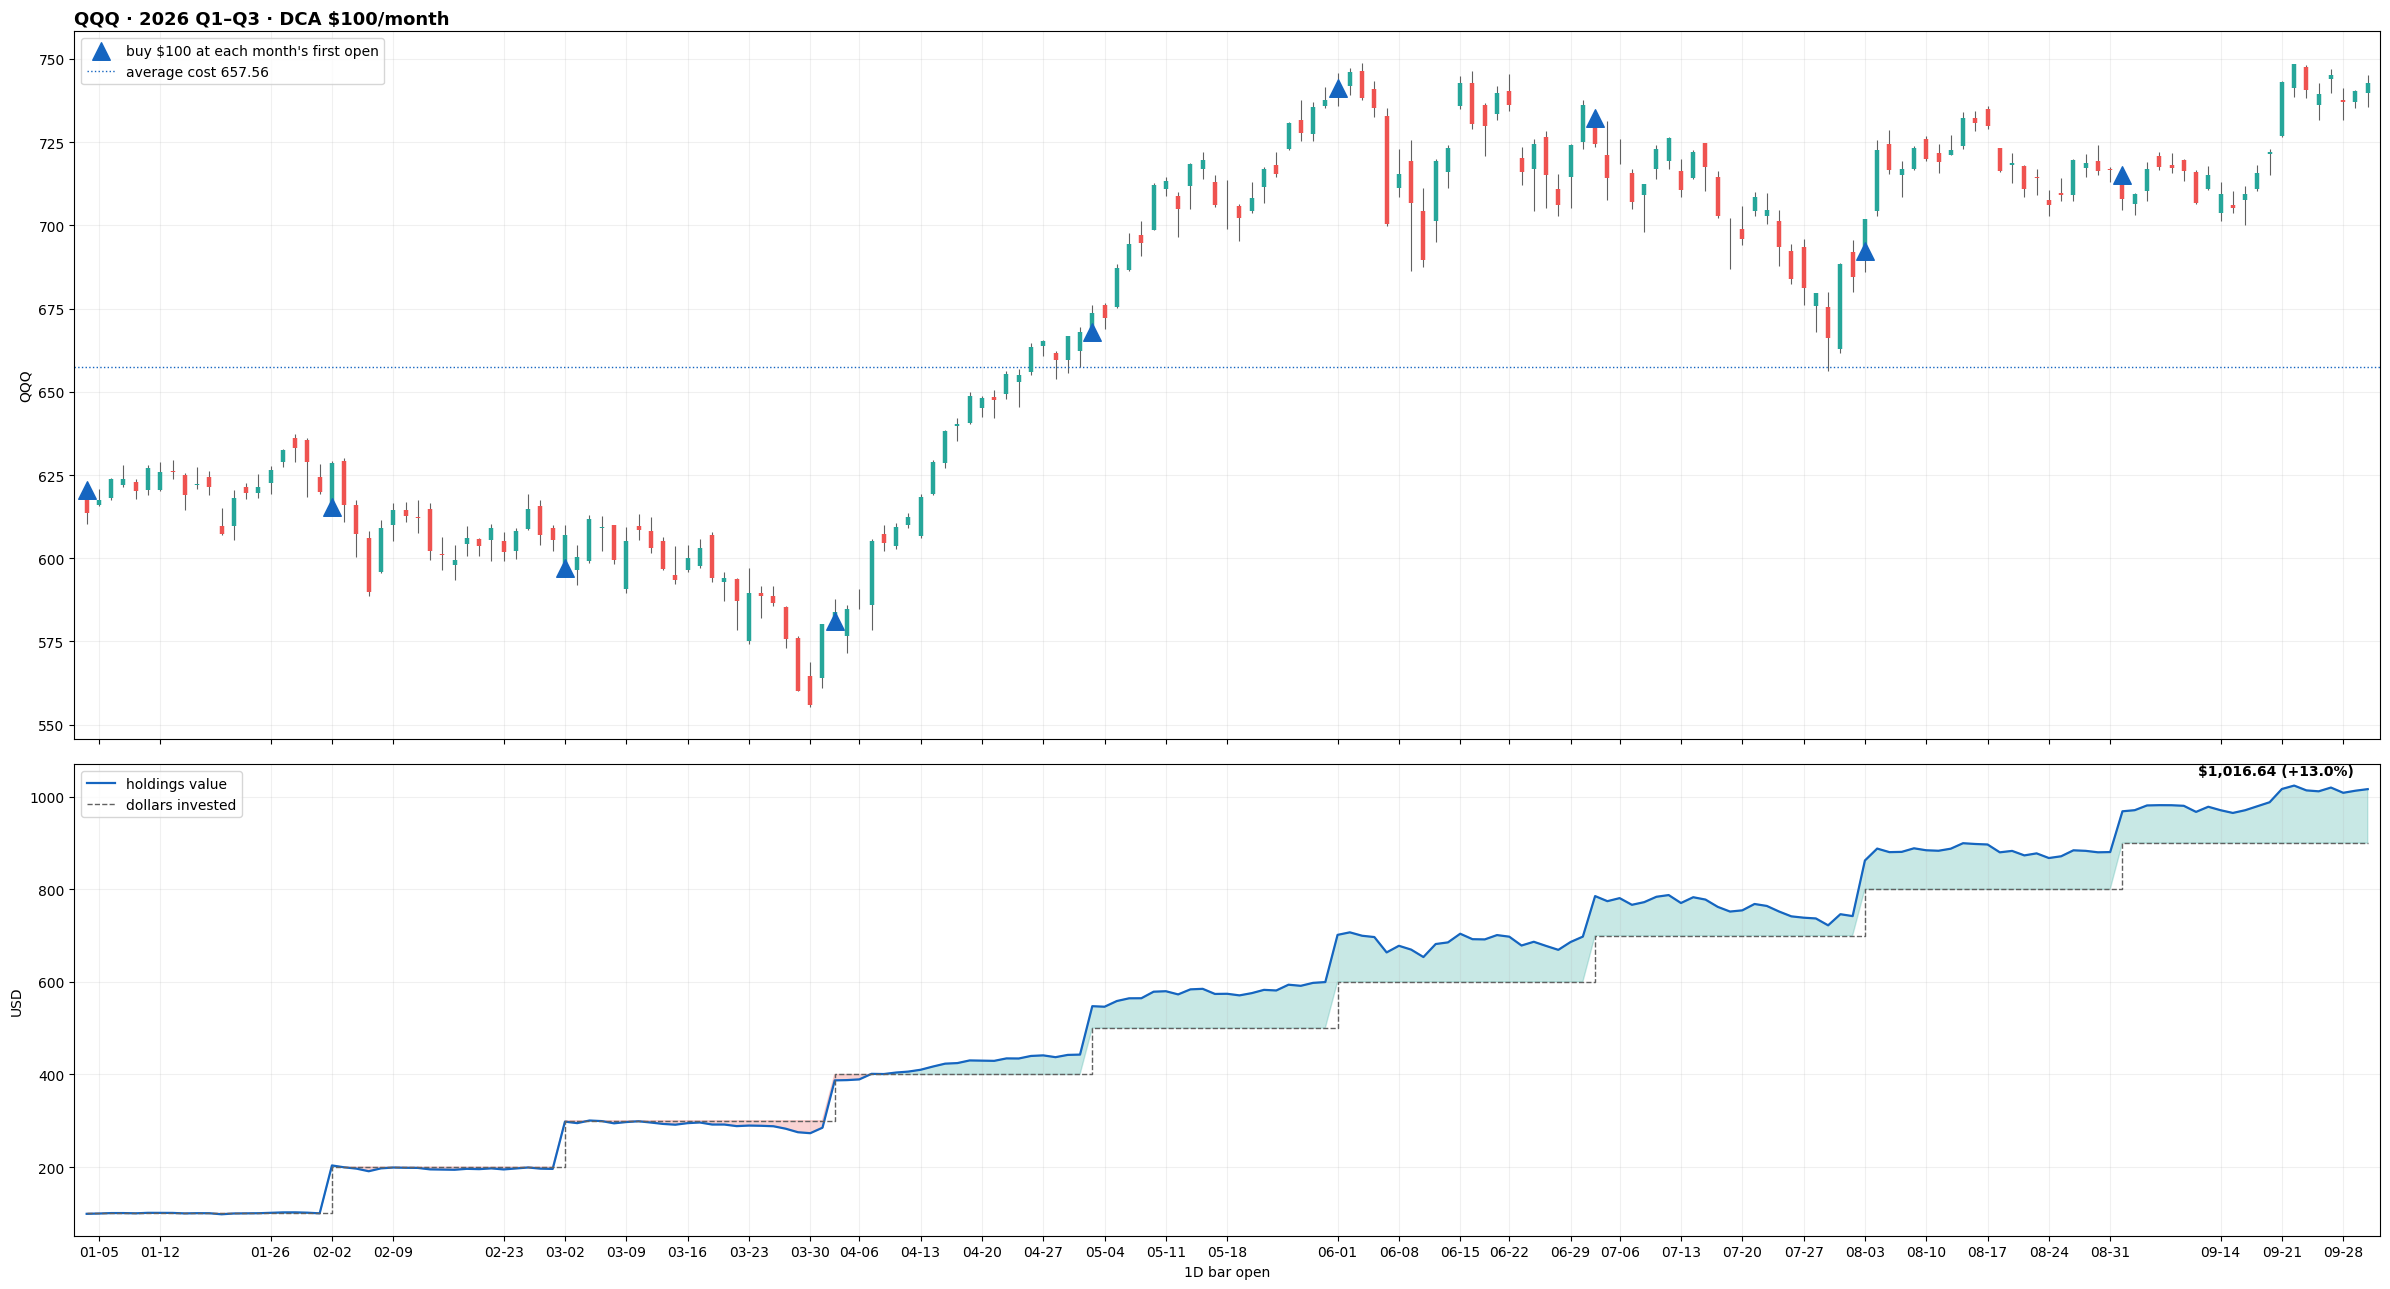

In [6]:
plot_dca(bars["QQQ"], f"QQQ · {LABEL} · DCA $100/month", "QQQ")